# Project 1: Transactions – Pass 08



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



> We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

> This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.




## Data Collection



#### 2. Load Pandas, Numpy, and Matplotlib modules

In [92]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [93]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

- Set number of columns and rows for this pass:

In [94]:
# set cols and rows for pass
num_cols = 50
num_rows = 50_000

num_cols, num_rows

(50, 50000)

- Read in the data from .csv using pandas:

In [95]:
# make dataframe
df = pd.read_csv(
    url,
    usecols=range(num_cols),
    nrows=num_rows,
)

- Check the dataframe:

In [96]:
# check dataframe
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


## Data Cleaning



#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [97]:
# define target_col
target_col = 'target'
target_col

'target'

- head

In [98]:
# head
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.285,16.552,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- tail

In [99]:
# tail
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN
49999,49999,train_49999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- shape

In [100]:
# shape
df.shape

(50000, 50)

- size

In [101]:
# size
df.size

2500000

- info

In [102]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 50 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50000 non-null  int64  
 1   ID_code     50000 non-null  object 
 2   target      8506 non-null   float64
 3   var_0       8506 non-null   float64
 4   var_1       8506 non-null   float64
 5   var_2       8506 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       8506 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       8506 non-null   float64
 11  var_8       8506 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
 15  var_12      0 non-null      float64
 16  var_13      0 non-null      float64
 17  var_14      8506 non-null   float64
 18  var_15      8506 non-null   float64
 19  var_16      0 non-null   

- describe

In [103]:
# describe
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
count,50000.000000,8506.000000,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,8506.000000,...,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,0.0,0.0,0.0
mean,24999.500000,0.098754,7.433406,15.873152,12.743673,NaN,-0.666477,NaN,NaN,1.216609,...,3.335911,19.317877,18.439225,NaN,5.768740,NaN,NaN,NaN,NaN,NaN
std,14433.901067,0.298349,2.998493,3.026206,4.167618,NaN,5.989788,NaN,NaN,5.206295,...,4.541526,5.013834,4.398037,NaN,7.462482,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,-0.482300,7.193400,1.263600,NaN,-20.962200,NaN,NaN,-12.739600,...,-13.999500,5.133100,6.673300,NaN,-15.121100,NaN,NaN,NaN,NaN,NaN
25%,12499.750000,0.000000,5.192575,13.822750,9.709300,NaN,-4.915275,NaN,NaN,-2.600700,...,0.018500,15.712475,15.044250,NaN,0.638225,NaN,NaN,NaN,NaN,NaN
50%,24999.500000,0.000000,7.286950,15.971650,12.660600,NaN,-0.585350,NaN,NaN,1.209900,...,3.366600,19.318800,18.293700,NaN,5.958900,NaN,NaN,NaN,NaN,NaN
75%,37499.250000,0.000000,9.523925,18.092725,15.755275,NaN,3.615725,NaN,NaN,5.146000,...,6.482825,22.906000,21.907575,NaN,11.427175,NaN,NaN,NaN,NaN,NaN
max,49999.000000,1.000000,16.716500,24.508500,25.848100,NaN,15.973100,NaN,NaN,18.419700,...,17.686100,33.940300,31.018900,NaN,26.401100,NaN,NaN,NaN,NaN,NaN


- nunique

In [104]:
# nunique
df.nunique()

,0
Unnamed: 0,50000
ID_code,50000
target,2
var_0,8168
var_1,8157
var_2,8247
var_3,0
var_4,8320
var_5,0
var_6,0


- unique

In [105]:
# unique
df[target_col].unique()

array([nan,  0.,  1.])

- isnull

In [106]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
var_6,50000
var_5,50000
var_11,50000
var_12,50000
var_3,50000
var_13,50000
var_9,50000
var_10,50000
var_42,50000
var_40,50000


In [107]:
# isnull frequencies
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
var_6,100.000
var_5,100.000
var_11,100.000
var_12,100.000
var_3,100.000
var_13,100.000
var_9,100.000
var_10,100.000
var_42,100.000
var_40,100.000


- dtypes

In [108]:
# dtypes
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


In [109]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(2204362)

#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [110]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
target,
NaN,41494
0.0,7666
1.0,840


In [111]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
target,
NaN,82.988
0.0,15.332
1.0,1.680


In [112]:
# target col size/shape
df[[target_col]].shape[0]

50000

In [113]:
# sum of nulls in target
df[[target_col]].isnull().sum()

,0
target,41494


In [114]:
# view number of null again
df.isnull().sum()

,0
Unnamed: 0,0
ID_code,0
target,41494
var_0,41494
var_1,41494
var_2,41494
var_3,50000
var_4,41494
var_5,50000
var_6,50000


In [115]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == 50000]

,0
var_3,50000
var_5,50000
var_6,50000
var_9,50000
var_10,50000
var_11,50000
var_12,50000
var_13,50000
var_16,50000
var_18,50000


In [116]:
# show columns with non-null values
df.isnull().sum()[df.isnull().sum() != 50000]

,0
Unnamed: 0,0
ID_code,0
target,41494
var_0,41494
var_1,41494
var_2,41494
var_4,41494
var_7,41494
var_8,41494
var_14,41494


In [117]:
# show only features
df.isnull().sum()[df.isnull().sum() != 50000][3:]

,0
var_0,41494
var_1,41494
var_2,41494
var_4,41494
var_7,41494
var_8,41494
var_14,41494
var_15,41494
var_17,41494
var_20,41494


In [118]:
# make list of columns with all nulls
list_nulls = list(df.isnull().sum()[df.isnull().sum() == 50000].keys())
list_nulls

['var_3',
 'var_5',
 'var_6',
 'var_9',
 'var_10',
 'var_11',
 'var_12',
 'var_13',
 'var_16',
 'var_18',
 'var_19',
 'var_23',
 'var_25',
 'var_30',
 'var_31',
 'var_32',
 'var_33',
 'var_34',
 'var_35',
 'var_40',
 'var_42',
 'var_43',
 'var_44',
 'var_45',
 'var_46']

In [119]:
# count the number of
len(list_nulls)

25

- Summary:

  - target column: 'target'
  - feature columns: 'var_0' - 'var_46'
  - identifier columns: 'Unnamed', 'ID_code'
  - null columns: 25 (see above)
  - null rows (target): 41494

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [120]:
# head again to double-check
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.285,16.552,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [121]:
# 1. 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped; target and var_0 - var_11 will be kept
# 2. 8314 null target columns should be dropped
# 3. 6 null feature columns should be dropped
# 4. After this, drop rows for any column with low null count
# 5. Finally, impute remaining nulls with column medians

- backup 1

In [122]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


In [123]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


In [124]:
# keep the target and all features
df = df.drop( columns = ['Unnamed: 0', 'ID_code'] )

In [125]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,6.0973,6.6596,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


- backup 2

In [126]:
# backup 2
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,6.0973,6.6596,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


In [127]:
# restore from backup 2
df = df_bak2.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,6.0973,6.6596,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


In [128]:
# preview filtering rows for where target is not null
df.loc[df[target_col].isnull() == False]

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,NaN,6.8990,NaN,NaN,4.8721,6.8599,...,9.6584,13.8385,15.1992,NaN,11.0333,NaN,NaN,NaN,NaN,NaN
49987,0.0,5.5247,19.5976,15.6233,NaN,10.3419,NaN,NaN,4.6616,6.6762,...,1.4398,25.3678,16.4867,NaN,11.9542,NaN,NaN,NaN,NaN,NaN
49988,0.0,4.5371,19.5715,12.0498,NaN,0.0423,NaN,NaN,-2.0017,7.6199,...,4.4885,24.3734,14.8631,NaN,5.6670,NaN,NaN,NaN,NaN,NaN
49994,0.0,6.0671,20.1542,14.4645,NaN,4.7347,NaN,NaN,-2.6682,6.9684,...,6.8356,16.5689,24.1643,NaN,5.1754,NaN,NaN,NaN,NaN,NaN


In [129]:
# execute the drop
df = df.loc[df[target_col].isnull() == False].copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,NaN,6.8990,NaN,NaN,4.8721,6.8599,...,9.6584,13.8385,15.1992,NaN,11.0333,NaN,NaN,NaN,NaN,NaN
49987,0.0,5.5247,19.5976,15.6233,NaN,10.3419,NaN,NaN,4.6616,6.6762,...,1.4398,25.3678,16.4867,NaN,11.9542,NaN,NaN,NaN,NaN,NaN
49988,0.0,4.5371,19.5715,12.0498,NaN,0.0423,NaN,NaN,-2.0017,7.6199,...,4.4885,24.3734,14.8631,NaN,5.6670,NaN,NaN,NaN,NaN,NaN
49994,0.0,6.0671,20.1542,14.4645,NaN,4.7347,NaN,NaN,-2.6682,6.9684,...,6.8356,16.5689,24.1643,NaN,5.1754,NaN,NaN,NaN,NaN,NaN


In [130]:
# backup 3
df_bak3 = df.copy()
df_bak3

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,NaN,6.8990,NaN,NaN,4.8721,6.8599,...,9.6584,13.8385,15.1992,NaN,11.0333,NaN,NaN,NaN,NaN,NaN
49987,0.0,5.5247,19.5976,15.6233,NaN,10.3419,NaN,NaN,4.6616,6.6762,...,1.4398,25.3678,16.4867,NaN,11.9542,NaN,NaN,NaN,NaN,NaN
49988,0.0,4.5371,19.5715,12.0498,NaN,0.0423,NaN,NaN,-2.0017,7.6199,...,4.4885,24.3734,14.8631,NaN,5.6670,NaN,NaN,NaN,NaN,NaN
49994,0.0,6.0671,20.1542,14.4645,NaN,4.7347,NaN,NaN,-2.6682,6.9684,...,6.8356,16.5689,24.1643,NaN,5.1754,NaN,NaN,NaN,NaN,NaN


In [131]:
# restore from backup
df = df_bak3.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,NaN,6.8990,NaN,NaN,4.8721,6.8599,...,9.6584,13.8385,15.1992,NaN,11.0333,NaN,NaN,NaN,NaN,NaN
49987,0.0,5.5247,19.5976,15.6233,NaN,10.3419,NaN,NaN,4.6616,6.6762,...,1.4398,25.3678,16.4867,NaN,11.9542,NaN,NaN,NaN,NaN,NaN
49988,0.0,4.5371,19.5715,12.0498,NaN,0.0423,NaN,NaN,-2.0017,7.6199,...,4.4885,24.3734,14.8631,NaN,5.6670,NaN,NaN,NaN,NaN,NaN
49994,0.0,6.0671,20.1542,14.4645,NaN,4.7347,NaN,NaN,-2.6682,6.9684,...,6.8356,16.5689,24.1643,NaN,5.1754,NaN,NaN,NaN,NaN,NaN


In [132]:
# review null list
list_nulls

['var_3',
 'var_5',
 'var_6',
 'var_9',
 'var_10',
 'var_11',
 'var_12',
 'var_13',
 'var_16',
 'var_18',
 'var_19',
 'var_23',
 'var_25',
 'var_30',
 'var_31',
 'var_32',
 'var_33',
 'var_34',
 'var_35',
 'var_40',
 'var_42',
 'var_43',
 'var_44',
 'var_45',
 'var_46']

In [133]:
# preview drop null columns
df.drop( columns = list_nulls )

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [134]:
# drop columns
df = df.drop( columns = list_nulls )
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [135]:
# make a backup
df_bak4 = df.copy()
df_bak4

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [136]:
# restore from backup
df = df_bak4.copy()
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [137]:
# look for nulls in new cleaned data frame
df.isnull().sum().sort_values( ascending = False )

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


In [162]:
# check total null counts sum
df.isnull().sum().sum()

np.int64(0)

In [138]:
# No more null values, so we're done! ( skip numbers 4 and 5 from above :D )

## Exploratory Data Analysis

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>,
        <Axes: title={'center': 'var_1'}>,
        <Axes: title={'center': 'var_2'}>,
        <Axes: title={'center': 'var_4'}>],
       [<Axes: title={'center': 'var_7'}>,
        <Axes: title={'center': 'var_8'}>,
        <Axes: title={'center': 'var_14'}>,
        <Axes: title={'center': 'var_15'}>,
        <Axes: title={'center': 'var_17'}>],
       [<Axes: title={'center': 'var_20'}>,
        <Axes: title={'center': 'var_21'}>,
        <Axes: title={'center': 'var_22'}>,
        <Axes: title={'center': 'var_24'}>,
        <Axes: title={'center': 'var_26'}>],
       [<Axes: title={'center': 'var_27'}>,
        <Axes: title={'center': 'var_28'}>,
        <Axes: title={'center': 'var_29'}>,
        <Axes: title={'center': 'var_36'}>,
        <Axes: title={'center': 'var_37'}>],
       [<Axes: title={'center': 'var_38'}>,
        <Axes: title={'center': 'var_39'}>,
        <Axes: title={'center': 'v

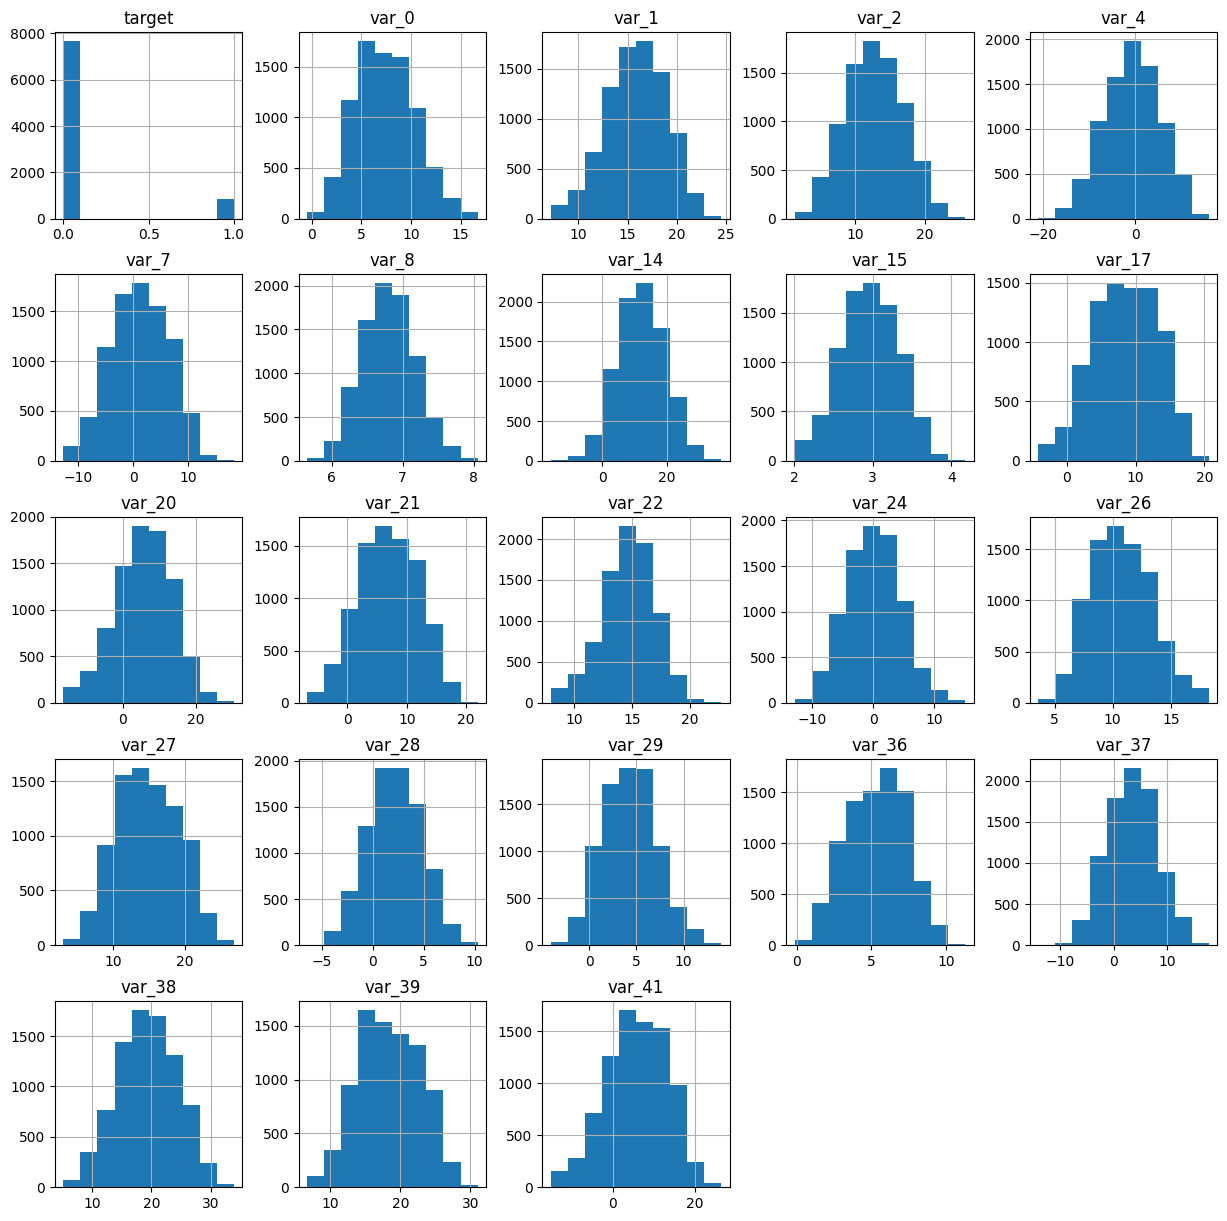

In [140]:
# Display a histogram
df.hist(figsize=(15, 15))

<Axes: >

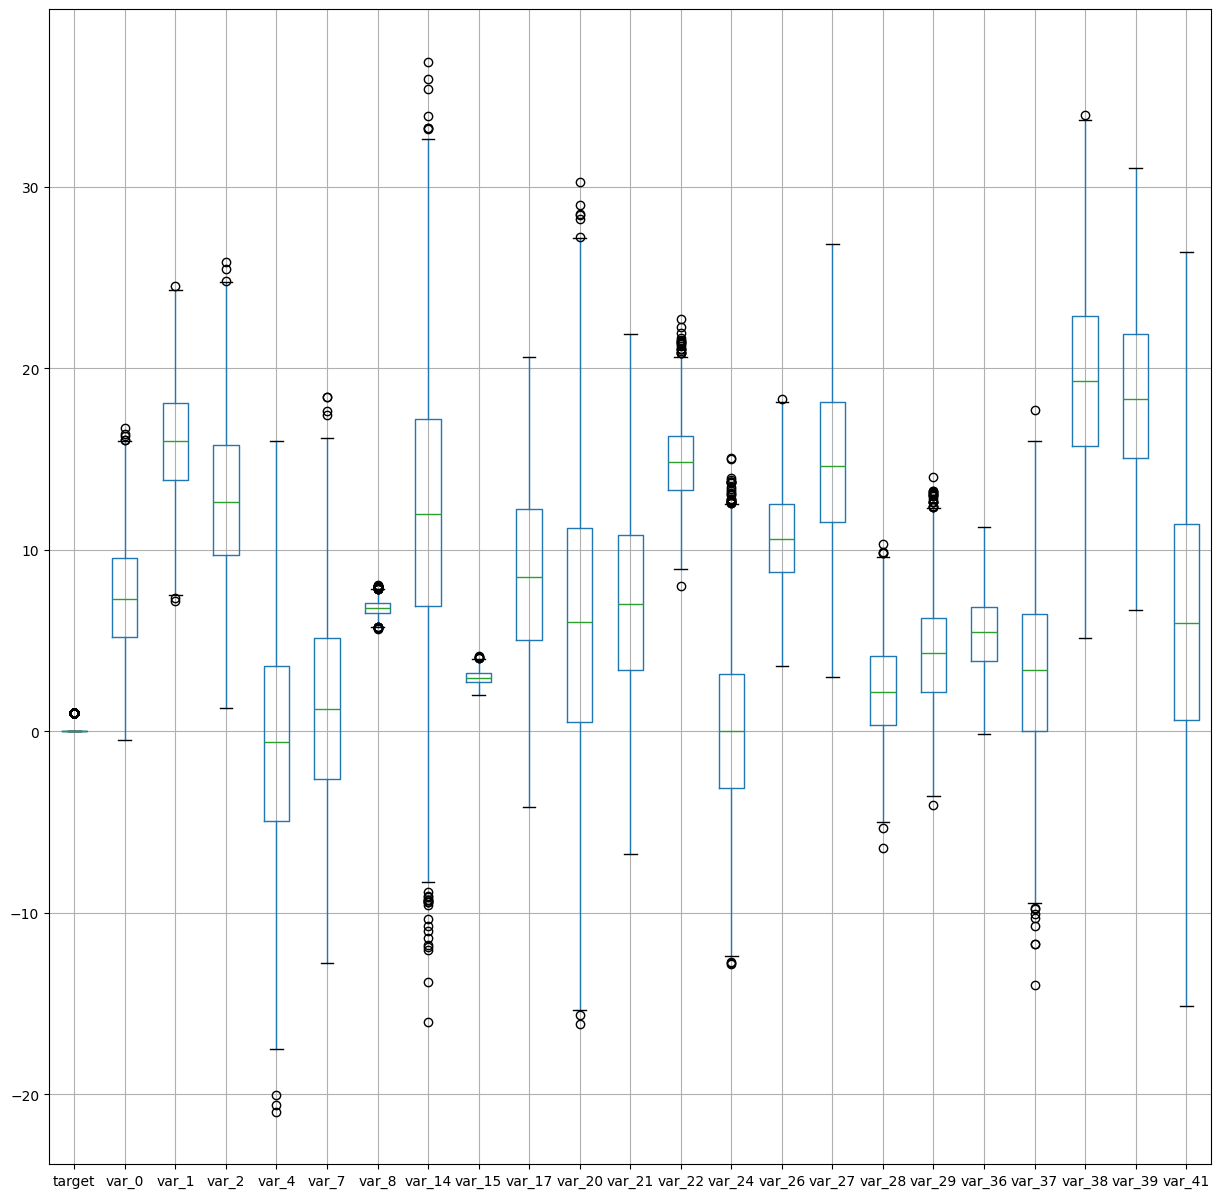

In [141]:
# display a boxplot
df.boxplot(figsize=(15, 15))

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [142]:
# column correlations
column_correlations = df.corr()
column_correlations

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
target,1.000000,0.050742,-0.039794,-0.060256,0.040229,-0.032706,0.048383,0.033708,-0.065024,-0.049189,...,0.045689,0.067268,-0.022421,-0.060705,0.049314,0.068738,0.041962,-0.057738,-0.038984,-0.059291
var_0,0.050742,1.000000,-0.001932,-0.002008,-0.004065,0.013920,0.005287,0.009787,0.003501,0.007570,...,0.007211,0.005079,-0.004578,0.001237,-0.010036,-0.008809,-0.000133,0.008856,0.007700,-0.004688
var_1,-0.039794,-0.001932,1.000000,-0.003072,0.019840,-0.010907,-0.010460,-0.013714,-0.001477,-0.002532,...,0.008056,-0.001995,-0.014325,0.003370,-0.010688,0.004288,-0.003056,-0.009136,0.008635,0.022035
var_2,-0.060256,-0.002008,-0.003072,1.000000,0.005686,-0.004277,0.004333,-0.005864,-0.003963,0.001795,...,0.007867,-0.002776,0.015401,0.003564,-0.004052,-0.018087,0.015591,-0.000161,0.011820,0.010744
var_4,0.040229,-0.004065,0.019840,0.005686,1.000000,-0.002771,-0.011529,0.002493,0.006865,-0.007378,...,0.017775,0.005338,0.005084,-0.013891,-0.001566,0.012709,-0.016146,-0.004427,-0.014136,0.001761
var_7,-0.032706,0.013920,-0.010907,-0.004277,-0.002771,1.000000,-0.017535,-0.016141,0.008960,0.007287,...,-0.008173,-0.001197,-0.011280,0.019048,-0.018282,-0.020851,-0.005682,-0.005131,-0.007425,-0.013643
var_8,0.048383,0.005287,-0.010460,0.004333,-0.011529,-0.017535,1.000000,-0.009329,0.006170,-0.006333,...,-0.003171,-0.011689,-0.001915,-0.005399,0.001543,0.007754,0.013471,-0.000151,0.010374,-0.019808
var_14,0.033708,0.009787,-0.013714,-0.005864,0.002493,-0.016141,-0.009329,1.000000,-0.002979,-0.002384,...,0.005116,-0.006524,-0.003718,-0.009721,-0.004758,0.021196,0.010578,0.005441,0.003580,-0.002742
var_15,-0.065024,0.003501,-0.001477,-0.003963,0.006865,0.008960,0.006170,-0.002979,1.000000,0.010272,...,0.006346,-0.025542,0.015068,0.004778,-0.000226,0.000304,0.013914,0.002860,0.012712,0.020895
var_17,-0.049189,0.007570,-0.002532,0.001795,-0.007378,0.007287,-0.006333,-0.002384,0.010272,1.000000,...,0.003891,-0.030515,-0.016135,-0.002544,0.003126,0.013883,-0.004958,0.022471,-0.004214,0.015237


<Axes: >

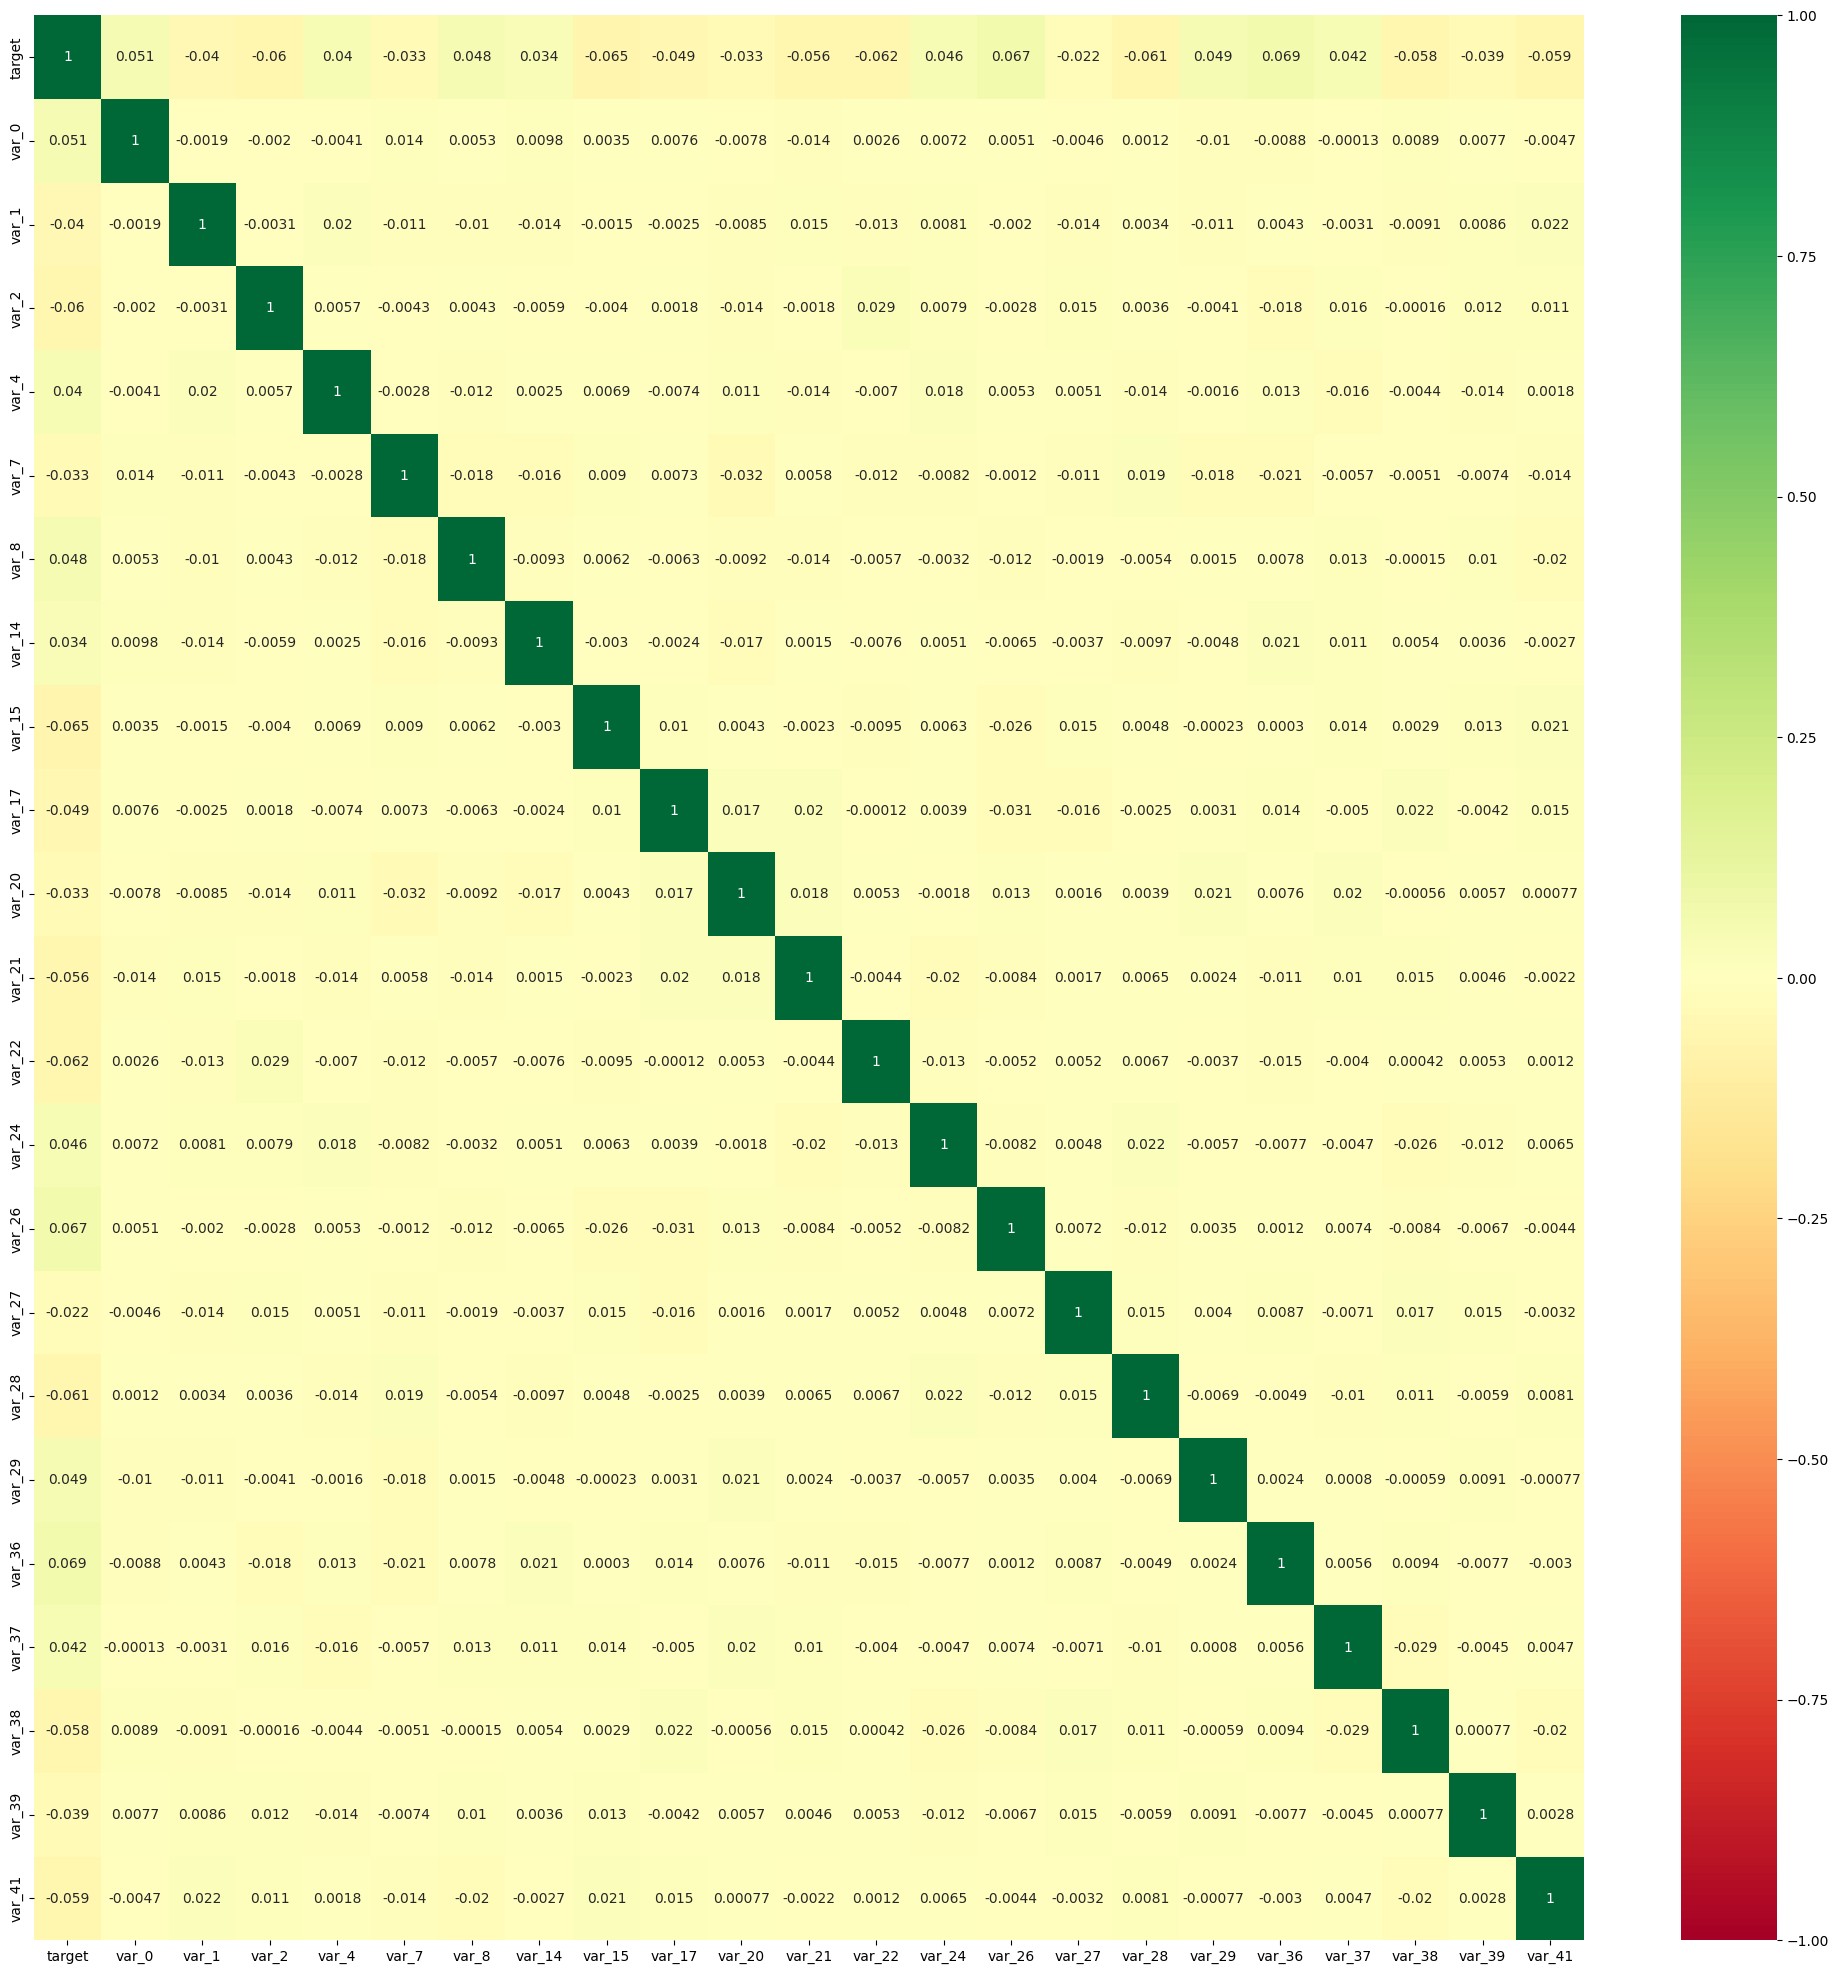

In [145]:
# Display correlation matrix
plt.figure(figsize = (25, 25))
sns.heatmap(
    column_correlations,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [146]:
# make successful (copy)
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,...,-2.7898,15.6807,15.8042,-0.7178,10.9340,4.8133,6.0355,20.8630,23.4864,13.7843
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,...,0.0653,9.1420,15.4289,6.5918,-2.0259,3.7186,3.1484,16.6982,10.0623,11.1803
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,...,1.9623,10.9316,13.8416,-1.2516,5.4594,7.5845,11.4284,22.4911,8.5086,-0.5054
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,...,-6.3648,7.7223,16.0343,4.0420,3.9460,3.1585,-2.9568,13.2129,14.8926,9.7548
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,...,-2.4131,11.2126,14.2569,7.7905,6.2622,10.0599,-2.1624,16.4613,19.2741,10.2073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49902,1.0,8.2904,17.1945,8.5822,-7.8052,1.5056,7.2934,15.7498,2.8284,1.6247,...,-2.0792,12.9012,8.4764,0.4621,2.8766,8.9584,5.9147,28.0406,8.2701,9.4408
49904,1.0,6.4266,16.4047,8.5837,3.9365,-2.5616,6.4823,9.6728,2.4021,10.1441,...,-4.4107,14.3413,19.1539,4.9267,-0.5488,4.5685,10.6816,18.2968,17.5007,13.6881
49951,1.0,6.9543,18.0159,17.2590,6.6750,5.4577,6.1337,20.7577,3.4378,12.3140,...,-4.3018,12.5175,21.5029,5.1779,4.5790,6.9567,0.5933,7.2596,10.8393,9.9556
49963,1.0,5.3376,14.1622,8.9636,-3.1775,8.5136,6.8919,13.6797,3.2751,16.0133,...,-7.6432,9.9926,14.6449,0.5069,4.7126,7.0827,4.8705,22.3385,16.0878,17.0267


In [147]:
# make unsuccessful (copy)
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


## Data Processing



### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [148]:
# make target and features
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [149]:
# check target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
49986,0.0
49987,0.0
49988,0.0
49994,0.0


In [150]:
# check target value counts
target.value_counts()

,count
target,
0.0,7666
1.0,840


In [151]:
# check target dimensions and type
type(target), target.shape, target.ndim

(pandas.core.series.Series, (8506,), 1)

In [152]:
# check features
features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,0.5878,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,6.5456,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,18.7893,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,1.1400,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,7.8002,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,0.1899,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,18.0065,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,-0.3680,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,5.1217,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [153]:
# check features dimensions and type
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (8506, 22), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [154]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [155]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [156]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [157]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [158]:
# Calculate the accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.9003291020216267

#### 16. Present a confusion matrix and heatmap



Text(113.9222222222222, 0.5, 'Predicted')

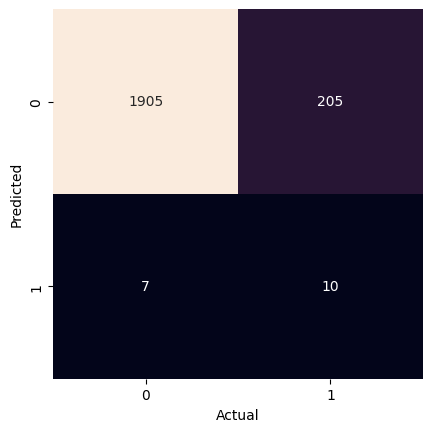

In [159]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [160]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True, zero_division = 0)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.902844,0.996339,0.947290,1912.000000
1.0,0.588235,0.046512,0.086207,215.000000
accuracy,0.900329,0.900329,0.900329,0.900329
macro avg,0.745539,0.521425,0.516748,2127.000000
weighted avg,0.871043,0.900329,0.860250,2127.000000


In [161]:
# Save variable values
X_train_SCV = X_train
X_test_SCV  = X_test
y_train_SCV = y_train
y_test_SCV  = y_test
y_pred_SCV  = y_pred

Conclusions (Brief):

- The accuracy for this larger subset of the large data set was about the same but a little lower, at about exactly 90%. Again, this is about as good as random, in that it matches the 90-10 unsuccessful-to-successful split.
- Like with the smaller data set, the number of true positives rose a bit with the additional data, to 10 / 2127 (where before it was 0).
- The number of false positives also rose to 7.
- The number of false negatives proportionally remained about the same, moving just a bit from 46 / 422, just over 10%, to 205 / 2127, just under 10%, which is a marginal improvement.


Future Work:
- bigger data subset (or set?)
- other types of validation?
- other types of data set balancing (upsampling?)
- different model